# Stage 2 - Exploratory Data Analysis

Objective:
- Understand demand, sales, pricing, inventory, seasonality, promotions, events and product behaviour before feature engineering or modelling.

EDA findings will be used to decide:
- useful features
- target definition
- important product segments
- price/demand relationships
- inventory-risk signals

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/raw/SmartMarkdown_Data_Dev_2024_2025.xlsx"

df = pd.read_excel(file_path,sheet_name="Historical_Weekly_Data")

df = df.sort_values(["SKU_ID", "Week_Start"]).reset_index(drop=True)

print("Shape:", df.shape)
print("SKUs:", df["SKU_ID"].nunique())
print("Date Range:", df["Week_Start"].min(), "to", df["Week_Start"].max())

Shape: (4200, 30)
SKUs: 40
Date Range: 2024-01-01 00:00:00 to 2025-12-29 00:00:00


In [36]:
# ---------------------------------------------------------
# Output directories
# ---------------------------------------------------------

from pathlib import Path

EDA_CHART_DIR = Path("../outputs/charts/eda")
TABLE_DIR = Path("../outputs/tables")

EDA_CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
# Overall Numerical columns summary

eda_numeric_cols = [
    "Units_Sold",
    "Latent_Demand",
    "Selling_Price",
    "Discount_Pct",
    "Opening_Inventory",
    "Available_Inventory",
    "Closing_Inventory",
    "Days_In_Inventory",
    "Views",
    "Cart_Adds",
    "Returns_Qty",
    "Revenue",
    "Gross_Profit",
    "Margin_Pct"
]

display(
    df[eda_numeric_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Units_Sold,4200.0,37.172857,17.317349,0.00,26.00,34.000,46.000,143.00
Latent_Demand,4200.0,38.015952,16.857965,6.00,26.00,35.000,47.000,143.00
Selling_Price,4200.0,2627.057429,2741.571004,179.40,1499.00,2061.000,3051.500,19999.00
Discount_Pct,4200.0,14.455952,11.813747,0.00,5.00,15.000,25.000,40.00
Opening_Inventory,4200.0,131.235714,79.454125,0.00,73.00,118.000,174.000,490.00
Available_Inventory,4200.0,162.112381,87.708576,0.00,100.00,147.000,208.000,557.00
Closing_Inventory,4200.0,126.854762,78.630423,0.00,69.00,115.000,170.000,490.00
Days_In_Inventory,4200.0,18.675000,15.138822,0.00,7.00,14.000,28.000,84.00
Views,4200.0,725.154524,378.350545,86.00,462.00,640.000,913.250,2894.00
Cart_Adds,4200.0,86.481905,48.196981,8.00,52.00,76.000,110.000,399.00


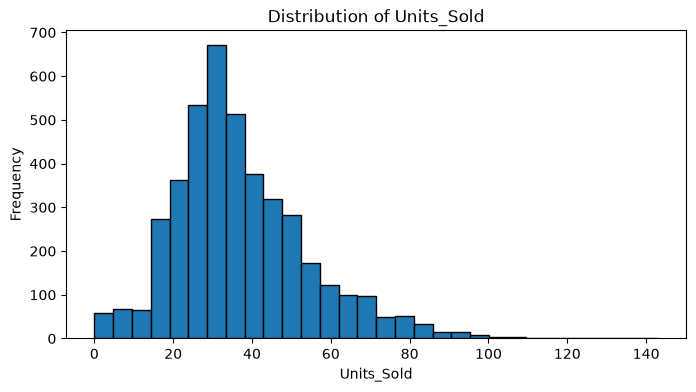

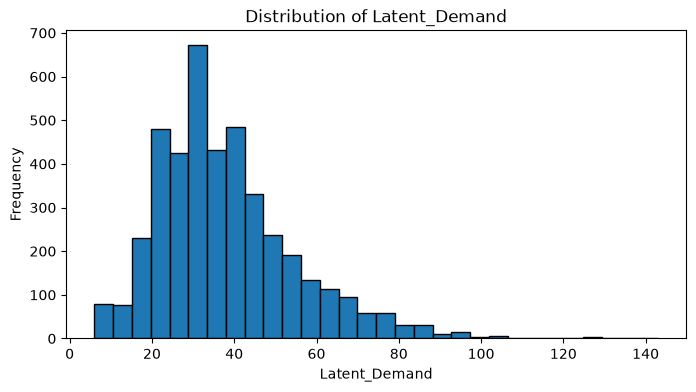

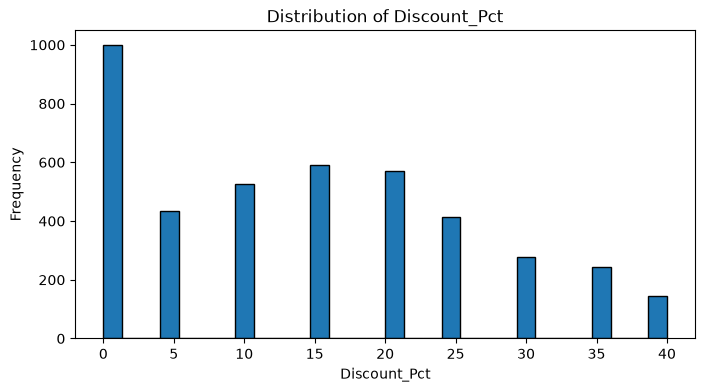

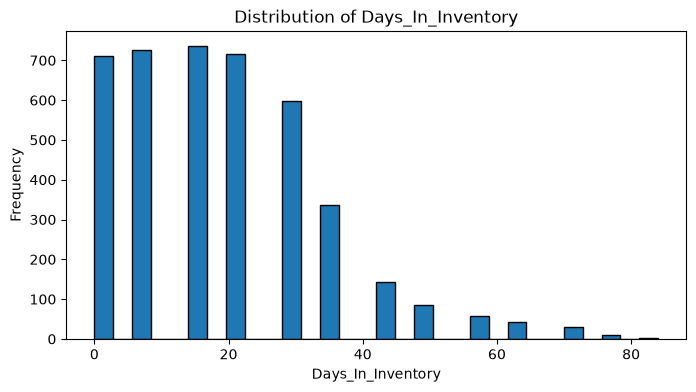

In [7]:
# Distribution Shapes

distribution_cols = [
    "Units_Sold",
    "Latent_Demand",
    "Discount_Pct",
    "Days_In_Inventory"
]

for col in distribution_cols:

    plt.figure(figsize=(8, 4))

    plt.hist(
        df[col],
        bins=30,
        edgecolor="black"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

## 1. Demand and Sales Behaviour

#### Objective
Understand the overall behaviour of weekly sales and underlying demand.

#### Reasoning
Units_Sold represents actual observed sales, while Latent_Demand represents
underlying customer demand. During stockouts, Units_Sold may be lower than
true demand.

This analysis helps us understand demand distribution and later decide the
appropriate regression target.

In [9]:
# ---------------------------------------------------------
# Demand and Sales Summary
# ---------------------------------------------------------
# Compare the central tendency, spread and range of
# Units_Sold and Latent_Demand.
# ---------------------------------------------------------

demand_cols = [
    "Units_Sold",
    "Latent_Demand"
]

display(df[demand_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Units_Sold,4200.0,37.172857,17.317349,0.0,26.0,34.0,46.0,143.0
Latent_Demand,4200.0,38.015952,16.857965,6.0,26.0,35.0,47.0,143.0


#### Distribution Analysis

We examine the distributions of Units_Sold and Latent_Demand to understand
their typical ranges, variability, skewness and possible extreme values.

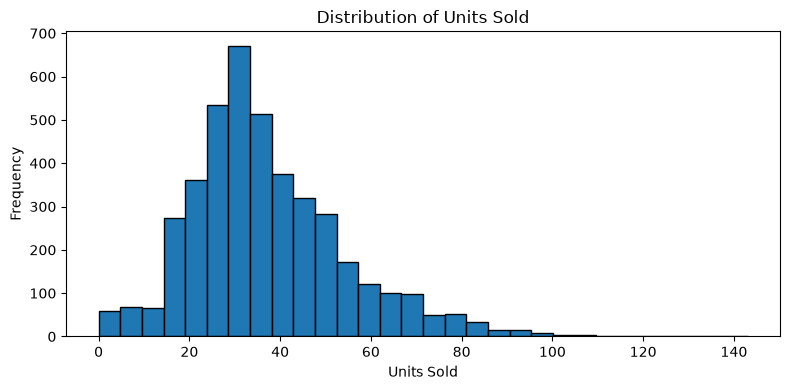

In [38]:
plt.figure(figsize=(8, 4))

plt.hist(
    df["Units_Sold"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    EDA_CHART_DIR / "units_sold_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

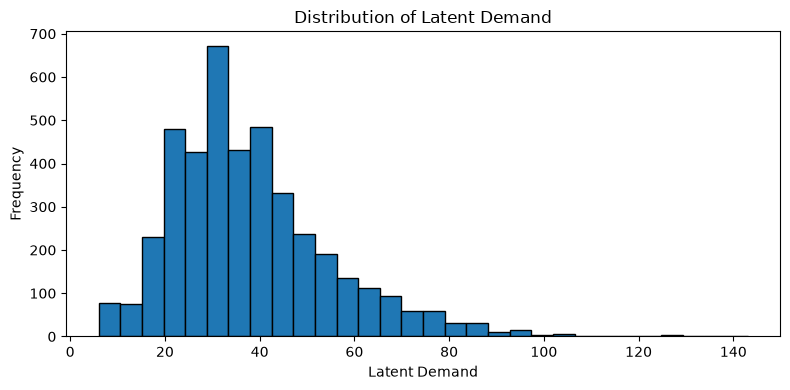

In [39]:
plt.figure(figsize=(8, 4))

plt.hist(
    df["Latent_Demand"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Latent Demand")
plt.xlabel("Latent Demand")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    EDA_CHART_DIR / "latent_demand_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Demand vs Observed Sales

We calculate the difference between Latent_Demand and Units_Sold.

A positive gap indicates that customer demand exceeded actual sales,
usually because available inventory limited the number of units that
could be sold.

In [12]:
df["Demand_Sales_Gap"] = (df["Latent_Demand"] - df["Units_Sold"])

print("Demand = Sales:",(df["Demand_Sales_Gap"] == 0).sum())

print("Demand > Sales:",(df["Demand_Sales_Gap"] > 0).sum())

print("\nPercentage where Demand = Sales:",round((df["Demand_Sales_Gap"] == 0).mean() * 100,2),"%")

print("Percentage where Demand > Sales:",round((df["Demand_Sales_Gap"] > 0).mean() * 100,2),"%")

Demand = Sales: 4088
Demand > Sales: 112

Percentage where Demand = Sales: 97.33 %
Percentage where Demand > Sales: 2.67 %


### Unmet Demand During Stockouts

For observations where demand exceeds sales, we measure the size of the
gap to understand how much demand was lost because of inventory constraints.

In [14]:
unmet_demand = df.loc[df["Demand_Sales_Gap"] > 0,"Demand_Sales_Gap"]

print("Average unmet demand:",round(unmet_demand.mean(), 2))

print("Median unmet demand:",round(unmet_demand.median(), 2))

print("Maximum unmet demand:",unmet_demand.max())

Average unmet demand: 31.62
Median unmet demand: 32.0
Maximum unmet demand: 92


### EDA Finding — Demand and Sales Behaviour

- Weekly Units_Sold and Latent_Demand show similar overall distributions.
- Average weekly sales are approximately 37 units, while average latent demand is approximately 38 units.
- Both variables are moderately right-skewed, with most observations concentrated in the lower-to-middle demand range and fewer high-demand weeks.
- In 97.33% of observations, Units_Sold equals Latent_Demand.
- In 2.67% of observations, demand exceeds observed sales because of stockout constraints.
- During these stockout periods, average unmet demand is 31.62 units.

**Modelling implication:** Units_Sold generally represents demand well, but stockout observations contain censored sales. The final regression target and treatment of stockout periods should therefore be evaluated carefully before modelling.

-----------------------

## 2. Product and Category Behaviour

#### Objective
Understand whether demand and sales behaviour differ across products and categories.

Different SKUs may have different baseline demand, variability and commercial behaviour.
Identifying these differences helps determine whether product/category information should
be used during feature engineering and later supports behavioural product clustering.

In [15]:
# ---------------------------------------------------------
# Category-Level Demand Profile
# ---------------------------------------------------------
# Compare typical sales and demand across product categories.
# ---------------------------------------------------------

category_demand = (
    df.groupby("Category")
    .agg(
        SKU_Count=("SKU_ID", "nunique"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Median_Units_Sold=("Units_Sold", "median"),
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Demand_Variability=("Latent_Demand", "std")
    )
    .round(2)
    .sort_values("Avg_Latent_Demand", ascending=False)
)

display(category_demand)

,SKU_Count,Avg_Units_Sold,Median_Units_Sold,Avg_Latent_Demand,Demand_Variability
Category,,,,,
Beauty,4,60.38,59.0,61.75,16.52
Sportswear,2,41.16,38.0,41.61,12.85
Apparel,12,39.89,38.0,41.03,16.08
Ethnic Wear,4,36.39,32.0,36.85,15.59
Footwear,6,34.93,33.0,35.52,9.97
Electronics,2,32.30,26.0,33.63,14.76
Accessories,4,32.26,30.5,32.94,9.13
Sports Equipment,5,22.81,22.0,23.35,10.77
Travel,1,21.52,22.0,21.72,4.79


In [16]:
# ---------------------------------------------------------
# SKU-Level Demand Profile
# ---------------------------------------------------------
# Identify differences in typical demand and variability
# between individual products.
# ---------------------------------------------------------

sku_demand = (
    df.groupby(
        ["SKU_ID", "Product_Name", "Category"]
    )
    .agg(
        Avg_Units_Sold=("Units_Sold", "mean"),
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Median_Demand=("Latent_Demand", "median"),
        Demand_Std=("Latent_Demand", "std"),
        Max_Demand=("Latent_Demand", "max")
    )
    .reset_index()
    .round(2)
    .sort_values("Avg_Latent_Demand", ascending=False)
)

display(sku_demand)

,SKU_ID,Product_Name,Category,Avg_Units_Sold,Avg_Latent_Demand,Median_Demand,Demand_Std,Max_Demand
36,SKU037,Vitamin C Face Wash,Beauty,74.76,75.94,72.0,15.80,134
0,SKU001,Men Cotton T-Shirt,Apparel,63.25,66.56,66.0,12.94,119
1,SKU002,Women Ribbed Top,Apparel,62.69,62.90,61.0,13.94,105
35,SKU036,Matte Liquid Lip Colour,Beauty,59.40,61.72,59.0,16.12,128
37,SKU038,Onion Hair Serum,Beauty,56.80,57.94,55.0,12.35,91
12,SKU013,Women Printed Kurta,Ethnic Wear,53.77,54.04,50.0,17.48,143
34,SKU035,Vitamin C Face Serum 30ml,Beauty,50.57,51.40,48.0,10.57,79
24,SKU025,Women Casual Sandals,Footwear,50.08,50.29,48.0,11.28,86
19,SKU020,Men Performance T-Shirt,Sportswear,48.90,48.90,46.0,13.87,92
38,SKU039,Wireless Bluetooth Earbuds,Electronics,45.25,46.87,46.0,8.54,76


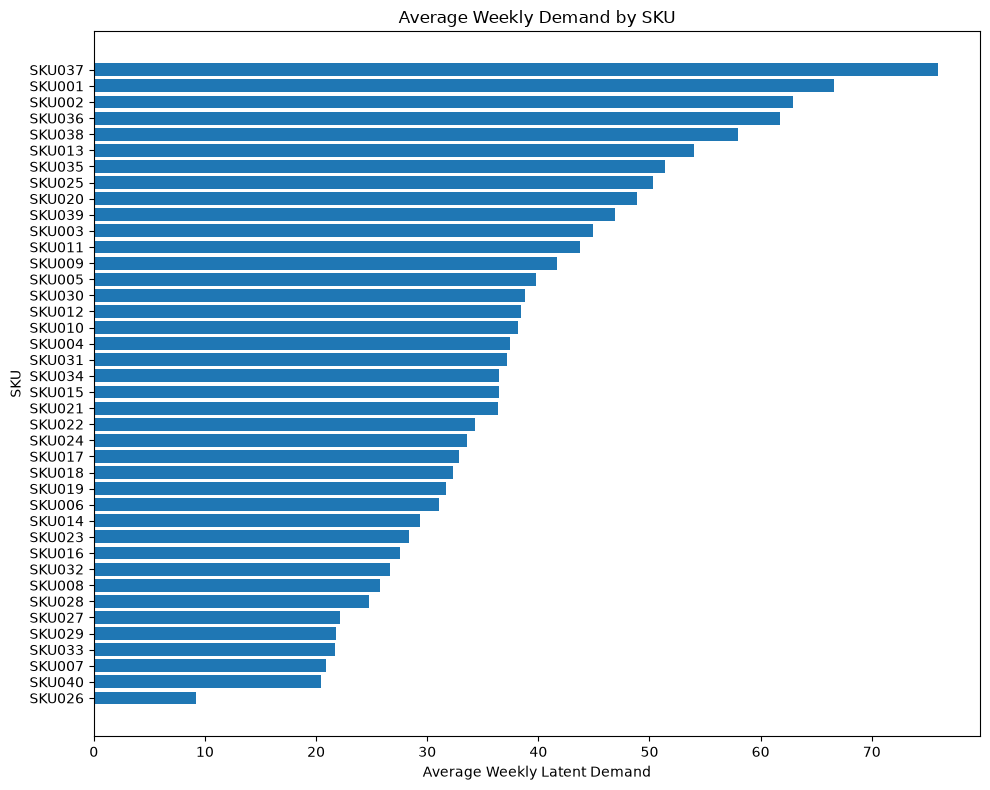

In [41]:
sku_plot = (
    sku_demand
    .sort_values("Avg_Latent_Demand")
)

plt.figure(figsize=(10, 8))

plt.barh(
    sku_plot["SKU_ID"],
    sku_plot["Avg_Latent_Demand"]
)

plt.xlabel("Average Weekly Latent Demand")
plt.ylabel("SKU")
plt.title("Average Weekly Demand by SKU")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/average_demand_by_sku.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EDA Finding — Product and Category Behaviour

- Demand differs substantially across categories and individual SKUs.
- Beauty has the highest average category-level demand, while Travel and Sports Equipment show relatively lower demand.
- Demand variability also differs across categories, indicating that some product groups are more stable than others.
- SKU-level average demand varies considerably, from roughly 9 units per week to more than 75 units per week.
- Significant variation also exists between SKUs within the same category.

**Modelling implication:** Category and SKU-level historical behaviour are likely to be important predictors of future demand. The variation across products also supports the planned use of product-level behavioural clustering.

---------------------------------

## 3. Temporal Demand Behaviour

#### Objective
Understand whether product demand changes over time and whether recurring
patterns exist across the two years.

#### Reasoning
If demand varies systematically by time, season or year, temporal features
and historical lag/rolling features may improve demand forecasting.

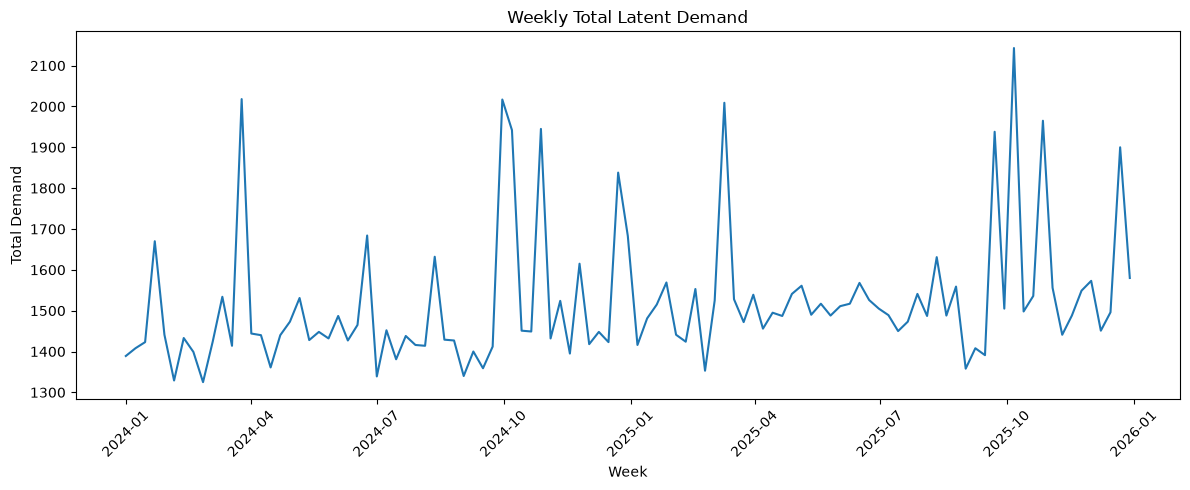

In [42]:
# ---------------------------------------------------------
# Overall Weekly Demand Trend
# ---------------------------------------------------------
# Aggregate demand across all SKUs for each week to inspect
# overall changes and recurring temporal patterns.
# ---------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_demand["Week_Start"],
    weekly_demand["Total_Latent_Demand"]
)

plt.title("Weekly Total Latent Demand")
plt.xlabel("Week")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/weekly_total_latent_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EDA Finding — Overall Weekly Demand

- Total weekly demand varies noticeably over time rather than remaining constant.
- Most weeks fall within a relatively stable demand range, but several sharp demand spikes are present.
- Higher-demand periods appear around similar parts of the year, suggesting possible seasonal or event-related effects.
- Further analysis is required to determine whether these peaks are driven by festivals, retail events, promotions, or specific product groups.

--------------

### Festival and Retail Event Impact

We compare demand during normal weeks, festival weeks and named retail-event weeks
to understand whether calendar events are associated with higher demand.

In [20]:
# Compare average demand for festival vs non-festival weeks

festival_demand = (
    df.groupby("Festival_Flag")
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean")
    )
    .round(2)
)

display(festival_demand)

,Avg_Latent_Demand,Avg_Units_Sold
Festival_Flag,,
0,36.83,36.23
1,49.29,46.16


In [21]:
# Compare average demand across named retail events

event_demand = (
    df[df["Retail_Event"].notna()]
    .groupby("Retail_Event")
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Avg_Discount=("Discount_Pct", "mean")
    )
    .round(2)
    .sort_values("Avg_Latent_Demand", ascending=False)
)

display(event_demand)

,Avg_Latent_Demand,Avg_Units_Sold,Avg_Discount
Retail_Event,,,
Dussehra,51.06,51.06,16.31
Holi,50.34,50.34,17.38
Navratri,49.44,49.44,16.19
Diwali,48.88,48.88,14.75
Christmas,46.72,31.11,15.50
Year End Sale,40.79,17.76,15.62
Independence Day Sale,40.79,40.79,18.38
Republic Day Sale,40.49,40.49,18.25
Black Friday,39.85,39.85,15.62


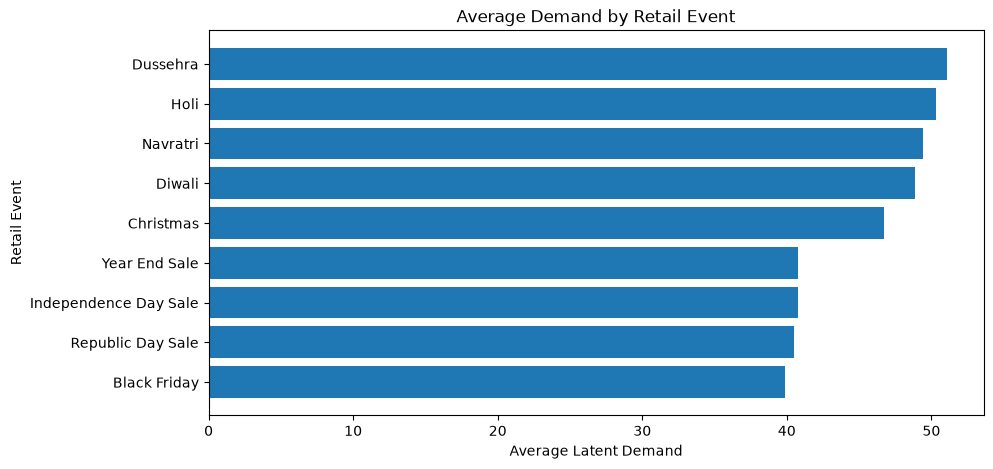

In [43]:
event_plot = event_demand.sort_values("Avg_Latent_Demand")

plt.figure(figsize=(10, 5))

plt.barh(
    event_plot.index,
    event_plot["Avg_Latent_Demand"]
)

plt.xlabel("Average Latent Demand")
plt.ylabel("Retail Event")
plt.title("Average Demand by Retail Event")
plt.savefig(
    "../outputs/charts/eda/average_demand_by_retail_event.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### EDA Finding — Festival and Retail Event Impact

- Festival weeks show clearly higher demand than non-festival weeks.
- Average latent demand during festival weeks is approximately 49.29 units compared with 36.83 units during non-festival weeks.
- Average observed sales also increase during festival periods, from approximately 36.23 to 46.16 units.
- Dussehra, Holi, Navratri and Diwali show the highest average event-level demand.
- Christmas and Year End Sale show a noticeable difference between latent demand and actual sales, indicating possible inventory constraints.
- Average discount levels are relatively similar across events, so the higher demand cannot be explained by discounting alone.

**Modelling implication:** Festival_Flag and Retail_Event appear to contain useful calendar information and should be considered during feature engineering. Event effects should still be interpreted together with inventory, promotion and pricing conditions.

-------------

## 4. Promotion and Markdown Behaviour

#### Objective
Understand whether promotional activity and discount levels are associated
with changes in product demand.

#### Reasoning
SmartMarkdown will later recommend discount scenarios, so we need to understand
how demand behaves during promoted and discounted periods before modelling
price response.

In [23]:
# ---------------------------------------------------------
# Promotion Impact on Demand
# ---------------------------------------------------------
# Compare average demand and sales during promoted
# and non-promoted weeks.
# ---------------------------------------------------------

promotion_summary = (
    df.groupby("Promotion_Flag")
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Avg_Discount=("Discount_Pct", "mean")
    )
    .round(2)
)

display(promotion_summary)

,Avg_Latent_Demand,Avg_Units_Sold,Avg_Discount
Promotion_Flag,,,
0,35.96,35.83,13.61
1,43.54,40.78,16.72


#### Promotion Type Analysis

Different types of promotions may behave differently.
We compare demand and discount levels across promotion categories.

In [24]:
promotion_type_summary = (
    df.groupby("Promotion_Type")
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Avg_Discount=("Discount_Pct", "mean"),
        Observation_Count=("SKU_ID", "count")
    )
    .round(2)
    .sort_values("Avg_Latent_Demand", ascending=False)
)

display(promotion_type_summary)

,Avg_Latent_Demand,Avg_Units_Sold,Avg_Discount,Observation_Count
Promotion_Type,,,,
Festival Offer,49.29,46.16,16.02,400
Clearance,41.22,25.88,16.25,120
Promotional Markdown,40.28,40.18,17.26,620
Regular Price,35.96,35.83,13.61,3060


#### Demand by Discount Level

We compare average demand across the available discount levels to understand
whether larger markdowns are generally associated with stronger demand.

In [25]:
discount_demand = (
    df.groupby("Discount_Pct")
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Observation_Count=("SKU_ID", "count")
    )
    .round(2)
    .reset_index()
)

display(discount_demand)

,Discount_Pct,Avg_Latent_Demand,Avg_Units_Sold,Observation_Count
0,0,30.20,29.74,999
1,5,32.10,31.24,433
2,10,34.48,33.91,525
3,15,37.79,36.69,592
4,20,39.15,38.00,570
5,25,43.90,42.45,415
6,30,46.29,45.41,277
7,35,51.73,50.96,245
8,40,63.16,62.71,144


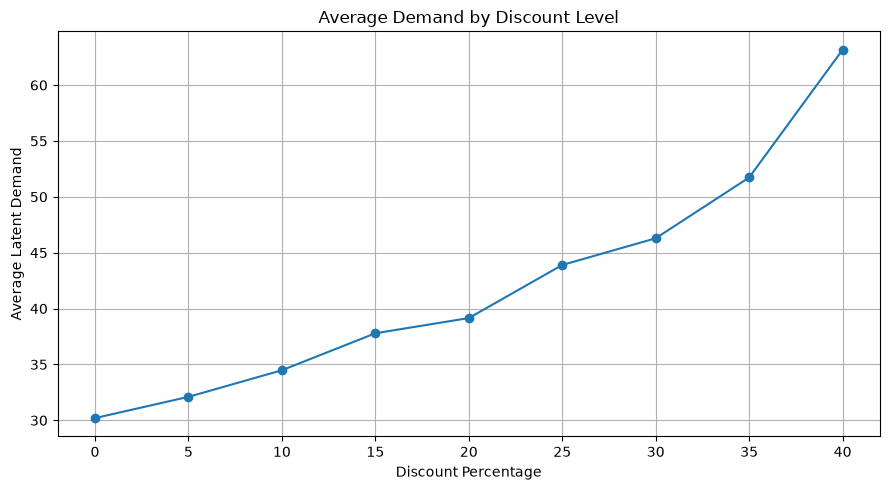

In [44]:
plt.figure(figsize=(9, 5))

plt.plot(
    discount_demand["Discount_Pct"],
    discount_demand["Avg_Latent_Demand"],
    marker="o"
)

plt.xlabel("Discount Percentage")
plt.ylabel("Average Latent Demand")
plt.title("Average Demand by Discount Level")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/average_demand_by_discount_level.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### EDA Finding — Promotion and Markdown Behaviour

- Promoted weeks show higher average latent demand and observed sales than non-promoted weeks.
- Promoted periods also have slightly higher average discounts, so promotion and discount effects should not be interpreted independently.
- Festival Offer periods show the highest average demand among promotion types.
- Clearance periods show a noticeable gap between latent demand and actual sales, indicating possible inventory constraints.
- Average demand increases consistently as discount percentage increases, suggesting a strong positive association between markdown depth and demand.

**Modelling implication:** 
- Promotion_Type, Promotion_Flag and Discount_Pct are likely to be important demand predictors.
- However, discount-response should later be evaluated within SKU/category because the global relationship may be influenced by product mix, events and inventory conditions.

----------------

## 5. Discount–Demand Relationship Within Product Groups

#### Objective
Check whether the positive relationship between discount and demand also appears
within categories and individual SKUs.

#### Reasoning
The global discount-demand relationship may be influenced by product mix,
events or promotions. SmartMarkdown needs product-level price response, so
the relationship should be evaluated within comparable product groups.

In [27]:
# ---------------------------------------------------------
# Discount-Demand Correlation by Category
# ---------------------------------------------------------
# Measure how Discount_Pct and Latent_Demand move together
# within each category.
# ---------------------------------------------------------

category_discount_corr = (
    df.groupby("Category")
    .apply(
        lambda x: x["Discount_Pct"].corr(x["Latent_Demand"]),
        include_groups=False
    )
    .reset_index(name="Discount_Demand_Correlation")
)

category_discount_corr["Discount_Demand_Correlation"] = category_discount_corr["Discount_Demand_Correlation"].round(3)

display(
    category_discount_corr.sort_values(
        "Discount_Demand_Correlation",
        ascending=False
    )
)

,Category,Discount_Demand_Correlation
8,Travel,0.720
0,Accessories,0.684
7,Sportswear,0.653
5,Footwear,0.631
2,Beauty,0.573
4,Ethnic Wear,0.477
6,Sports Equipment,0.476
1,Apparel,0.454
3,Electronics,0.443


#### SKU-Level Discount Response

We calculate the relationship between discount and latent demand separately
for each SKU to check whether products respond differently to markdowns.

In [28]:
sku_discount_corr = (
    df.groupby("SKU_ID")
    .apply(
        lambda x: x["Discount_Pct"].corr(x["Latent_Demand"]),
        include_groups=False
    )
    .reset_index(name="Discount_Demand_Correlation")
)

sku_discount_corr["Discount_Demand_Correlation"] = sku_discount_corr["Discount_Demand_Correlation"].round(3)

display(sku_discount_corr.sort_values("Discount_Demand_Correlation",ascending=False))

,SKU_ID,Discount_Demand_Correlation
29,SKU030,0.912
21,SKU022,0.852
18,SKU019,0.842
23,SKU024,0.841
2,SKU003,0.824
27,SKU028,0.824
37,SKU038,0.818
19,SKU020,0.801
38,SKU039,0.795
16,SKU017,0.789


In [29]:
print(sku_discount_corr["Discount_Demand_Correlation"].describe().round(3))

count    40.000
mean      0.724
std       0.105
min       0.476
25%       0.707
50%       0.750
75%       0.789
max       0.912
Name: Discount_Demand_Correlation, dtype: float64


In [30]:
print("SKUs with positive correlation:",(sku_discount_corr["Discount_Demand_Correlation"] > 0).sum())

print("SKUs with correlation > 0.5:",(sku_discount_corr["Discount_Demand_Correlation"] > 0.5).sum())

SKUs with positive correlation: 40
SKUs with correlation > 0.5: 37


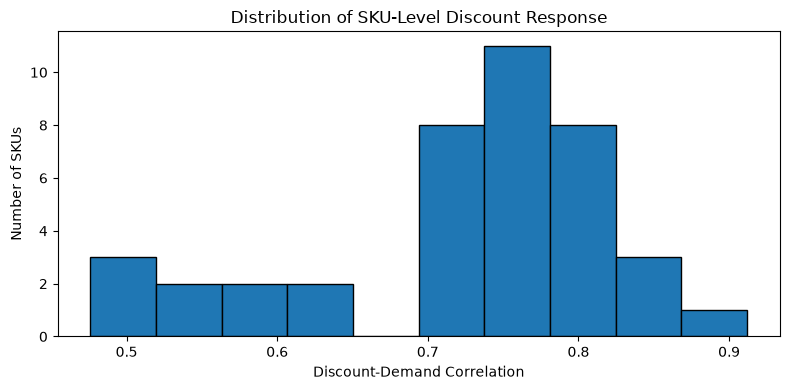

In [45]:
plt.figure(figsize=(8, 4))

plt.hist(
    sku_discount_corr["Discount_Demand_Correlation"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Discount-Demand Correlation")
plt.ylabel("Number of SKUs")
plt.title("Distribution of SKU-Level Discount Response")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/sku_discount_response_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### EDA Finding — Discount Response by Category and SKU

- All product categories show a positive relationship between discount percentage and latent demand.
- Category-level correlations range from approximately 0.44 to 0.72.
- All 40 SKUs show positive discount-demand correlation.
- 37 out of 40 SKUs have correlation greater than 0.5.
- The average SKU-level correlation is approximately 0.72, indicating that most products show a relatively strong historical association between higher discounts and higher demand.
- The strength of the relationship varies across products, suggesting that markdown response is product-specific.

**Modelling implication:** Discount_Pct is an important candidate predictor. Product-level price response should later be estimated carefully and may require SKU-, category-, or cluster-level fallback logic.

--------------------

## 6. Inventory Behaviour

#### Objective
Understand how inventory levels behave relative to product demand and sales.

#### Reasoning
Markdown decisions should consider whether a product is overstocked, slow-moving,
or at risk of stockout. This analysis helps identify useful inventory-related
signals for the later recommendation engine.

In [31]:
# ---------------------------------------------------------
# Inventory Summary
# ---------------------------------------------------------
# Review the distribution and range of key inventory fields.
# ---------------------------------------------------------

inventory_cols = [
    "Opening_Inventory",
    "Available_Inventory",
    "Closing_Inventory",
    "Days_In_Inventory"
]

display(
    df[inventory_cols]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
Opening_Inventory,4200.0,131.235714,79.454125,0.0,73.0,118.0,174.0,490.0
Available_Inventory,4200.0,162.112381,87.708576,0.0,100.0,147.0,208.0,557.0
Closing_Inventory,4200.0,126.854762,78.630423,0.0,69.0,115.0,170.0,490.0
Days_In_Inventory,4200.0,18.675000,15.138822,0.0,7.0,14.0,28.0,84.0


#### SKU-Level Inventory Profile

We compare average closing inventory, inventory age, demand and stockout rate
across SKUs to identify slow-moving, high-stock and frequently constrained products.

In [33]:
sku_inventory = (
    df.groupby(
        ["SKU_ID", "Product_Name", "Category"]
    )
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Closing_Inventory=("Closing_Inventory", "mean"),
        Avg_Days_In_Inventory=("Days_In_Inventory", "mean"),
        Stockout_Rate=("Stockout_Flag", "mean")
    )
    .reset_index()
)

sku_inventory["Stockout_Rate"] = (sku_inventory["Stockout_Rate"] * 100).round(2)

sku_inventory = sku_inventory.round(2)

display(
    sku_inventory.sort_values(
        "Avg_Closing_Inventory",
        ascending=False
    )
)

,SKU_ID,Product_Name,Category,Avg_Latent_Demand,Avg_Closing_Inventory,Avg_Days_In_Inventory,Stockout_Rate
36,SKU037,Vitamin C Face Wash,Beauty,75.94,260.16,17.00,1.90
0,SKU001,Men Cotton T-Shirt,Apparel,66.56,224.55,19.73,5.71
1,SKU002,Women Ribbed Top,Apparel,62.90,218.75,20.47,0.95
35,SKU036,Matte Liquid Lip Colour,Beauty,61.72,201.37,20.33,4.76
37,SKU038,Onion Hair Serum,Beauty,57.94,193.13,19.87,1.90
34,SKU035,Vitamin C Face Serum 30ml,Beauty,51.40,182.41,17.53,1.90
12,SKU013,Women Printed Kurta,Ethnic Wear,54.04,176.12,18.00,0.95
38,SKU039,Wireless Bluetooth Earbuds,Electronics,46.87,158.85,21.60,3.81
19,SKU020,Men Performance T-Shirt,Sportswear,48.90,157.07,15.27,0.00
24,SKU025,Women Casual Sandals,Footwear,50.29,154.82,17.73,0.95


In [34]:
high_inventory_skus = (sku_inventory.sort_values(["Avg_Closing_Inventory", "Avg_Days_In_Inventory"],ascending=False).head(10))

display(high_inventory_skus)

,SKU_ID,Product_Name,Category,Avg_Latent_Demand,Avg_Closing_Inventory,Avg_Days_In_Inventory,Stockout_Rate
36,SKU037,Vitamin C Face Wash,Beauty,75.94,260.16,17.00,1.90
0,SKU001,Men Cotton T-Shirt,Apparel,66.56,224.55,19.73,5.71
1,SKU002,Women Ribbed Top,Apparel,62.90,218.75,20.47,0.95
35,SKU036,Matte Liquid Lip Colour,Beauty,61.72,201.37,20.33,4.76
37,SKU038,Onion Hair Serum,Beauty,57.94,193.13,19.87,1.90
34,SKU035,Vitamin C Face Serum 30ml,Beauty,51.40,182.41,17.53,1.90
12,SKU013,Women Printed Kurta,Ethnic Wear,54.04,176.12,18.00,0.95
38,SKU039,Wireless Bluetooth Earbuds,Electronics,46.87,158.85,21.60,3.81
19,SKU020,Men Performance T-Shirt,Sportswear,48.90,157.07,15.27,0.00
24,SKU025,Women Casual Sandals,Footwear,50.29,154.82,17.73,0.95


In [35]:
high_stockout_skus = (
    sku_inventory
    .sort_values(
        "Stockout_Rate",
        ascending=False
    )
    .head(10)
)

display(high_stockout_skus)

,SKU_ID,Product_Name,Category,Avg_Latent_Demand,Avg_Closing_Inventory,Avg_Days_In_Inventory,Stockout_Rate
0,SKU001,Men Cotton T-Shirt,Apparel,66.56,224.55,19.73,5.71
5,SKU006,Men Casual Overshirt,Apparel,31.10,98.58,18.93,5.71
28,SKU029,Trekking Backpack 30L,Sports Equipment,21.83,72.99,18.60,5.71
39,SKU040,Wireless Over-Ear Headphones,Electronics,20.40,71.26,21.00,5.71
17,SKU018,Unisex Sports Backpack,Accessories,32.33,102.66,17.53,4.76
8,SKU009,Men Slim Jeans,Apparel,41.72,144.06,18.67,4.76
35,SKU036,Matte Liquid Lip Colour,Beauty,61.72,201.37,20.33,4.76
20,SKU021,Unisex Casual Sneakers,Footwear,36.36,122.66,21.27,4.76
38,SKU039,Wireless Bluetooth Earbuds,Electronics,46.87,158.85,21.60,3.81
22,SKU023,Women Walking Shoes,Footwear,28.39,94.63,19.40,3.81


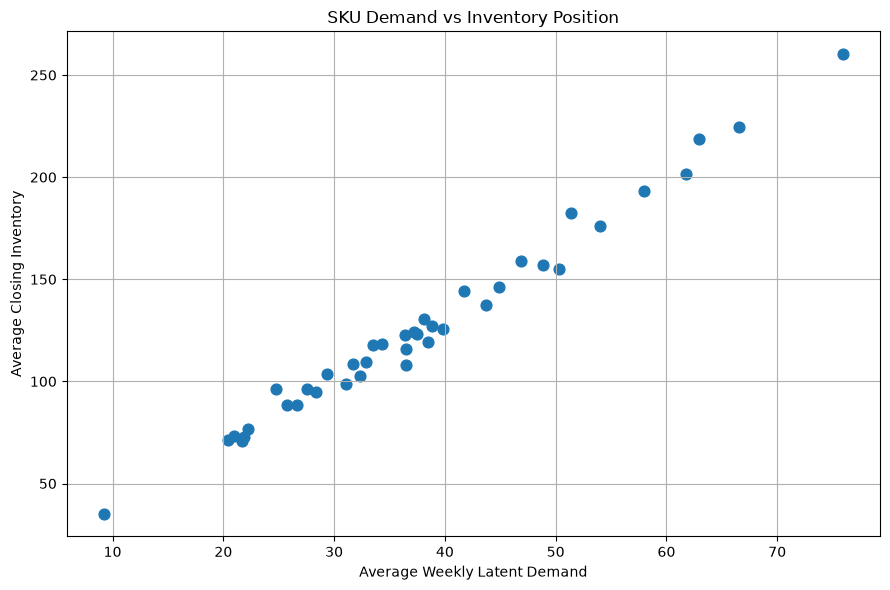

In [46]:
plt.figure(figsize=(9, 6))

plt.scatter(
    sku_inventory["Avg_Latent_Demand"],
    sku_inventory["Avg_Closing_Inventory"],
    s=60
)

plt.xlabel("Average Weekly Latent Demand")
plt.ylabel("Average Closing Inventory")
plt.title("SKU Demand vs Inventory Position")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/sku_demand_vs_inventory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### EDA Finding — Inventory Behaviour

- Inventory levels vary considerably across SKUs, with closing inventory ranging from 0 to 490 units.
- Some high-demand SKUs also maintain high inventory levels, showing that high stock alone does not necessarily indicate overstock.
- Stockout-prone products are not always the products with the highest inventory.
- Inventory risk should therefore be evaluated relative to product demand rather than using absolute inventory alone.
- Separate treatment is required for excess-inventory risk and stockout risk.

**Modelling implication:** Inventory-related features such as sell-through, weeks of supply, inventory pressure and expected leftover are likely to be more informative than raw inventory levels alone.

----------------

## 7. Competitor Price Behaviour

#### Objective
Understand whether product demand is associated with our selling price relative
to the competitor price.

#### Reasoning
Competitor pricing can influence customer purchase decisions. Before using
competitor price in demand modelling or markdown scenarios, we need to understand
whether relative price position shows meaningful differences in demand.

In [47]:
# ---------------------------------------------------------
# Competitor Price Gap
# ---------------------------------------------------------
# Positive gap  -> our product is more expensive
# Negative gap  -> our product is cheaper
# Gap near zero -> similar pricing
# ---------------------------------------------------------

df["Competitor_Gap_Pct"] = (
    (df["Selling_Price"] - df["Competitor_Price"])
    / df["Competitor_Price"]
    * 100
)

display(
    df["Competitor_Gap_Pct"]
    .describe()
    .round(2)
)

count    4200.00
mean        0.41
std         7.01
min       -14.29
25%        -5.00
50%         0.00
75%         5.56
max        15.38
Name: Competitor_Gap_Pct, dtype: float64

#### Creating simple price competitive groups

- < -5%       → Cheaper than competitor
- -5% to +5%  → Similar price
- +5% >       → More expensive than competitor

In [48]:
# ---------------------------------------------------------
# Competitive Price Position
# ---------------------------------------------------------

df["Price_Position"] = pd.cut(
    df["Competitor_Gap_Pct"],
    bins=[-np.inf, -5, 5, np.inf],
    labels=[
        "Cheaper than Competitor",
        "Similar Price",
        "More Expensive than Competitor"
    ]
)

print(
    df["Price_Position"]
    .value_counts()
)

Price_Position
Similar Price                     1859
More Expensive than Competitor    1227
Cheaper than Competitor           1114
Name: count, dtype: int64


In [49]:
# ---------------------------------------------------------
# Demand by Competitive Price Position
# ---------------------------------------------------------

competitor_summary = (
    df.groupby(
        "Price_Position",
        observed=True
    )
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Avg_Discount=("Discount_Pct", "mean"),
        Observation_Count=("SKU_ID", "count")
    )
    .round(2)
)

display(competitor_summary)

,Avg_Latent_Demand,Avg_Units_Sold,Avg_Discount,Observation_Count
Price_Position,,,,
Cheaper than Competitor,42.71,41.84,21.97,1114
Similar Price,36.80,35.88,11.57,1859
More Expensive than Competitor,35.60,34.90,12.01,1227


In [50]:
competitor_gap_corr = df[
    ["Competitor_Gap_Pct", "Latent_Demand"]
].corr().iloc[0, 1]

print(
    "Competitor Gap vs Latent Demand Correlation:",
    round(competitor_gap_corr, 3)
)

Competitor Gap vs Latent Demand Correlation: -0.149


Interpretation :

- Negative correlation: demand tends to decrease as our price becomes more expensive relative to competitor

- Positive correlation : opposite tendency

- Near zero : weak global relationship

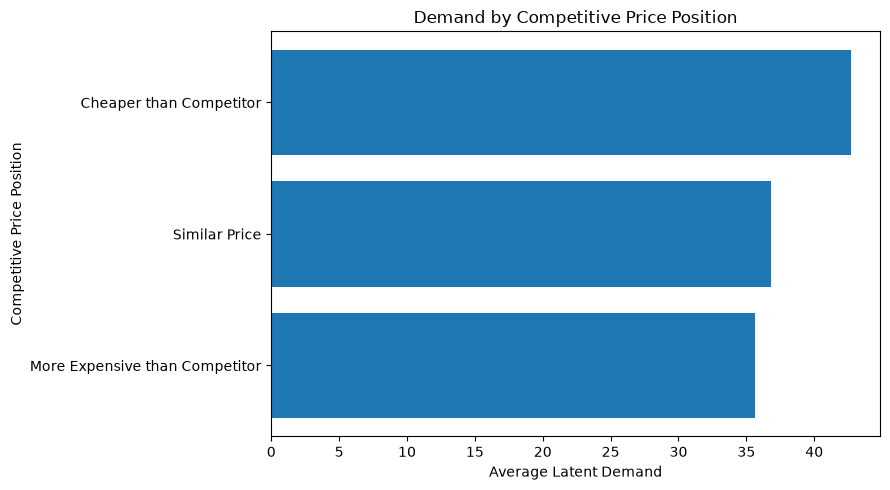

In [52]:
price_position_plot = (
    competitor_summary
    .sort_values("Avg_Latent_Demand")
)

plt.figure(figsize=(9, 5))

plt.barh(
    price_position_plot.index,
    price_position_plot["Avg_Latent_Demand"]
)

plt.xlabel("Average Latent Demand")
plt.ylabel("Competitive Price Position")
plt.title("Demand by Competitive Price Position")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/demand_by_competitive_price_position.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### EDA Finding — Competitor Price Behaviour

- The dataset contains observations where our product is cheaper than, similarly priced to, and more expensive than competitors.
- Average latent demand is highest when our selling price is more than 5% cheaper than the competitor price.
- Demand is lower when prices are similar or when our product is more expensive than the competitor.
- The overall correlation between Competitor_Gap_Pct and Latent_Demand is -0.149, indicating a weak negative relationship.
- This suggests that demand tends to decrease slightly as our relative price becomes more expensive.
- However, cheaper-than-competitor observations also have substantially higher average discounts, so competitor pricing should not be interpreted independently.

**Modelling implication:** Competitor_Price and Competitor_Gap_Pct may provide useful supporting information for demand prediction and markdown scenario evaluation, but they should be used together with Selling_Price, Discount_Pct, promotions and other demand drivers.

------------------

## 8. Profitability Behaviour

#### Objective
Understand how discounting affects margin and gross profit.

#### Reasoning
SmartMarkdown should not recommend the discount that only maximizes demand.
The final recommendation must also protect profitability, so we need to study
how margin and gross profit behave across different discount levels.

In [53]:
# ---------------------------------------------------------
# Profitability by Discount Level
# ---------------------------------------------------------
# Compare demand, margin and gross profit across
# different markdown levels.
# ---------------------------------------------------------

profitability_by_discount = (
    df.groupby("Discount_Pct")
    .agg(
        Avg_Latent_Demand=("Latent_Demand", "mean"),
        Avg_Units_Sold=("Units_Sold", "mean"),
        Avg_Margin_Pct=("Margin_Pct", "mean"),
        Avg_Gross_Profit=("Gross_Profit", "mean"),
        Observation_Count=("SKU_ID", "count")
    )
    .round(2)
    .reset_index()
)

display(profitability_by_discount)

,Discount_Pct,Avg_Latent_Demand,Avg_Units_Sold,Avg_Margin_Pct,Avg_Gross_Profit,Observation_Count
0,0,30.20,29.74,51.54,37100.05,999
1,5,32.10,31.24,49.22,33898.72,433
2,10,34.48,33.91,46.31,34306.64,525
3,15,37.79,36.69,42.83,30997.90,592
4,20,39.15,38.00,39.46,28471.34,570
5,25,43.90,42.45,36.39,25393.67,415
6,30,46.29,45.41,32.95,21975.87,277
7,35,51.73,50.96,28.32,18759.50,245
8,40,63.16,62.71,25.05,14538.68,144


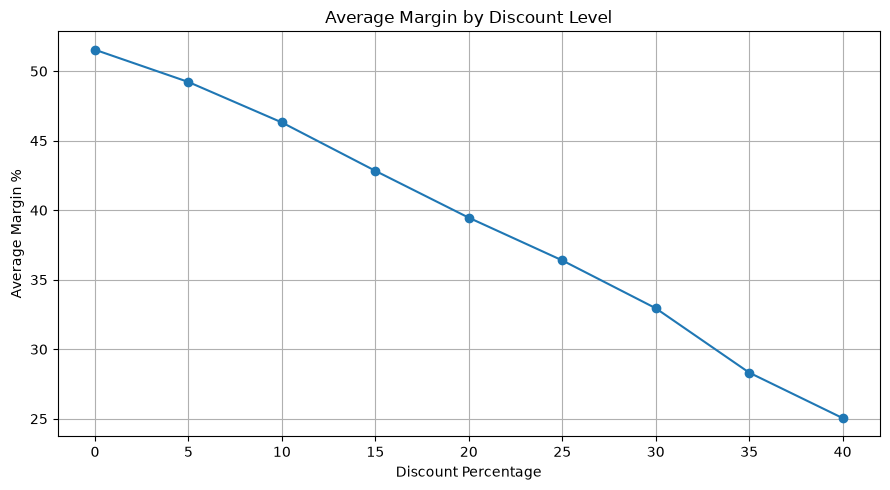

In [54]:
plt.figure(figsize=(9, 5))

plt.plot(
    profitability_by_discount["Discount_Pct"],
    profitability_by_discount["Avg_Margin_Pct"],
    marker="o"
)

plt.xlabel("Discount Percentage")
plt.ylabel("Average Margin %")
plt.title("Average Margin by Discount Level")

plt.grid(True)
plt.tight_layout()

plt.show()

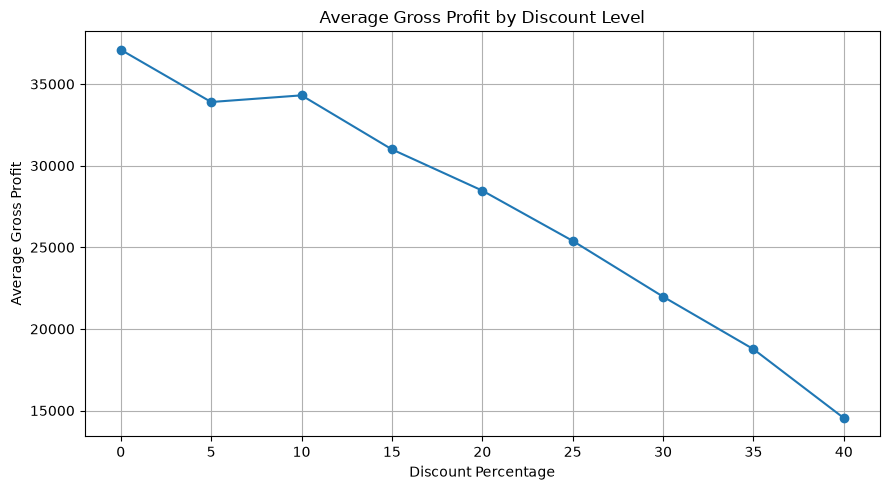

In [56]:
plt.figure(figsize=(9, 5))

plt.plot(
    profitability_by_discount["Discount_Pct"],
    profitability_by_discount["Avg_Gross_Profit"],
    marker="o"
)

plt.xlabel("Discount Percentage")
plt.ylabel("Average Gross Profit")
plt.title("Average Gross Profit by Discount Level")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/average_gross_profit_by_discount_level.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### EDA Finding — Profitability Behaviour

- Average demand increases steadily as discount percentage increases.
- Average margin decreases consistently as markdown depth increases.
- Average gross profit generally declines as discounts become deeper, despite the increase in demand.
- A small variation is observed between some neighbouring discount levels, but the overall profitability trend is clearly negative with deeper markdowns.
- Therefore, the discount level that produces the highest demand is not necessarily the most profitable discount.

**Modelling implication:** SmartMarkdown should not optimize markdowns based only on predicted demand or sales. The decision engine must evaluate demand improvement together with margin, expected gross profit and inventory-clearance objectives.

------------

## 9. Customer Interest Behaviour

#### Objective
Understand whether customer-interest signals such as product views and cart additions
are associated with product demand.

#### Reasoning
Views and Cart_Adds may provide early signals of customer purchase intent.
If they are meaningfully related to demand, historical or lagged versions of these
variables may be useful during demand forecasting.

In [60]:
# ---------------------------------------------------------
# Customer Interest vs Demand
# ---------------------------------------------------------
# Check the relationship between Views, Cart_Adds and Latent_Demand.
# ---------------------------------------------------------

interest_corr = (
    df[
        ["Views", "Cart_Adds", "Latent_Demand"]
    ]
    .corr()
    .round(3)
)

display(interest_corr)

,Views,Cart_Adds,Latent_Demand
Views,1.000,0.921,0.834
Cart_Adds,0.921,1.000,0.769
Latent_Demand,0.834,0.769,1.000


In [61]:
# ---------------------------------------------------------
# Cart Rate
# ---------------------------------------------------------
# Measures the proportion of product views that resulted in a cart addition.
# ---------------------------------------------------------

df["Cart_Rate"] = (df["Cart_Adds"] / df["Views"])

display(df["Cart_Rate"].describe().round(3))

count    4200.000
mean        0.120
std         0.023
min         0.078
25%         0.099
50%         0.120
75%         0.140
max         0.160
Name: Cart_Rate, dtype: float64

In [62]:
cart_rate_corr = df[
    ["Cart_Rate", "Latent_Demand"]
].corr().iloc[0, 1]

print(
    "Cart Rate vs Latent Demand Correlation:",
    round(cart_rate_corr, 3)
)

Cart Rate vs Latent Demand Correlation: -0.024


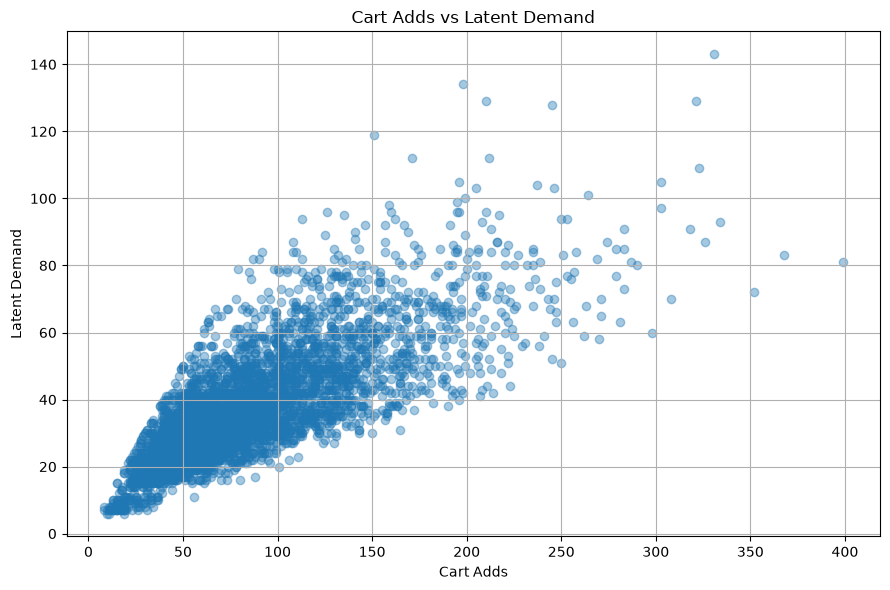

In [63]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Cart_Adds"],
    df["Latent_Demand"],
    alpha=0.4
)

plt.xlabel("Cart Adds")
plt.ylabel("Latent Demand")
plt.title("Cart Adds vs Latent Demand")

plt.grid(True)
plt.tight_layout()

plt.show()

#### EDA Finding — Customer Interest Behaviour

- Views and Cart_Adds show strong positive relationships with Latent_Demand.
- Views have a correlation of approximately 0.83 with demand, while Cart_Adds show a correlation of approximately 0.77.
- Views and Cart_Adds are also highly correlated with each other.
- Cart_Rate has almost no relationship with demand (correlation approximately -0.02).

**Modelling implication:** Historical or lagged Views and Cart_Adds may provide useful demand signals. Cart_Rate appears less informative for predicting demand and may not add much value as a standalone feature.

------------------

## 10. Correlation and Feature Relationship Overview

#### Objective
Review relationships among important numerical variables and identify features
that may contain similar information.

#### Reasoning
Correlation provides a compact view of how variables move together. It can help
identify potentially useful predictors as well as highly related features that
may become redundant during modelling.

Correlation is used here for exploration only and does not imply causation.

In [64]:
# ---------------------------------------------------------
# Selected Numerical Features for Correlation Analysis
# ---------------------------------------------------------

correlation_cols = [
    "Latent_Demand",
    "Units_Sold",
    "Discount_Pct",
    "Selling_Price",
    "Available_Inventory",
    "Closing_Inventory",
    "Days_In_Inventory",
    "Competitor_Gap_Pct",
    "Views",
    "Cart_Adds",
    "Margin_Pct",
    "Gross_Profit"
]

correlation_matrix = (
    df[correlation_cols]
    .corr()
    .round(2)
)

display(correlation_matrix)

,Latent_Demand,Units_Sold,Discount_Pct,Selling_Price,Available_Inventory,Closing_Inventory,Days_In_Inventory,Competitor_Gap_Pct,Views,Cart_Adds,Margin_Pct,Gross_Profit
Latent_Demand,1.00,0.94,0.44,-0.53,0.54,0.41,-0.02,-0.15,0.83,0.77,-0.05,-0.31
Units_Sold,0.94,1.00,0.42,-0.51,0.61,0.48,-0.09,-0.14,0.79,0.73,-0.05,-0.21
Discount_Pct,0.44,0.42,1.00,-0.20,0.06,-0.03,0.00,-0.28,0.37,0.35,-0.81,-0.42
Selling_Price,-0.53,-0.51,-0.20,1.00,-0.40,-0.34,0.03,0.08,-0.45,-0.42,-0.23,0.47
Available_Inventory,0.54,0.61,0.06,-0.40,1.00,0.99,-0.11,-0.03,0.45,0.42,0.22,-0.17
Closing_Inventory,0.41,0.48,-0.03,-0.34,0.99,1.00,-0.10,0.00,0.34,0.31,0.26,-0.14
Days_In_Inventory,-0.02,-0.09,0.00,0.03,-0.11,-0.10,1.00,-0.00,-0.02,-0.01,-0.02,-0.07
Competitor_Gap_Pct,-0.15,-0.14,-0.28,0.08,-0.03,0.00,-0.00,1.00,-0.12,-0.12,0.23,0.15
Views,0.83,0.79,0.37,-0.45,0.45,0.34,-0.02,-0.12,1.00,0.92,-0.04,-0.25
Cart_Adds,0.77,0.73,0.35,-0.42,0.42,0.31,-0.01,-0.12,0.92,1.00,-0.04,-0.23


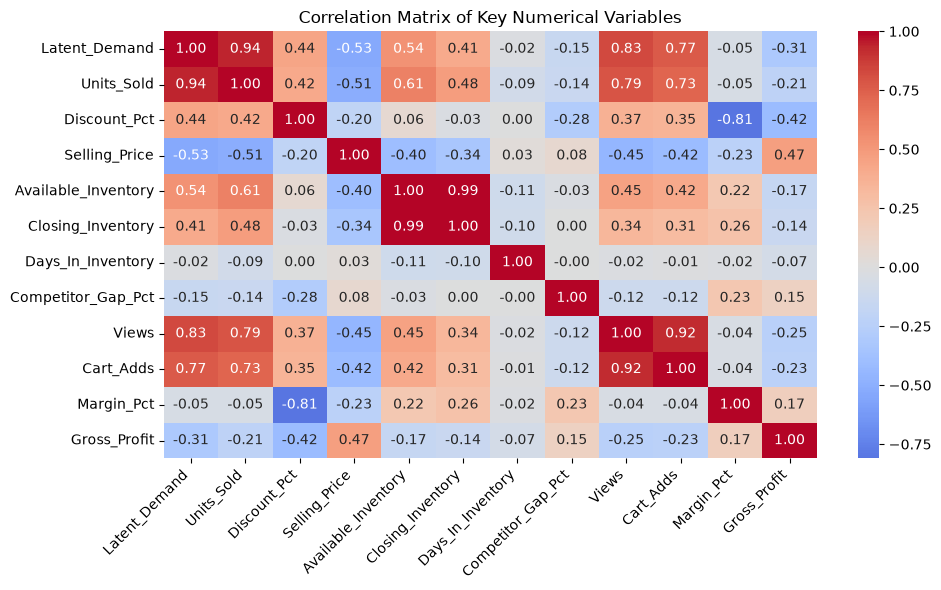

In [75]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.xticks(rotation=45, ha="right")
plt.title("Correlation Matrix of Key Numerical Variables")
plt.tight_layout()

plt.savefig(
    "../outputs/charts/eda/key_feature_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
# ---------------------------------------------------------
# Correlation of Numerical Features with Latent Demand
# ---------------------------------------------------------

demand_correlations = (
    correlation_matrix["Latent_Demand"]
    .drop("Latent_Demand")
    .sort_values(ascending=False)
)

display(
    demand_correlations.to_frame(
        name="Correlation_With_Latent_Demand"
    )
)

,Correlation_With_Latent_Demand
Units_Sold,0.94
Views,0.83
Cart_Adds,0.77
Available_Inventory,0.54
Discount_Pct,0.44
Closing_Inventory,0.41
Days_In_Inventory,-0.02
Margin_Pct,-0.05
Competitor_Gap_Pct,-0.15
Gross_Profit,-0.31


#### EDA Finding — Correlation and Feature Relationships

- Units_Sold has the strongest relationship with Latent_Demand (0.94), which is expected because observed sales equal underlying demand in most non-stockout periods.
- Views (0.83) and Cart_Adds (0.77) show strong positive relationships with demand and may provide useful historical customer-interest signals.
- Discount_Pct shows a moderate positive relationship with demand (0.44), supporting the earlier markdown-response analysis.
- Competitor_Gap_Pct has a weak negative relationship with demand (-0.15), suggesting that being more expensive than competitors may slightly reduce demand.
- Selling_Price has a moderate negative global correlation with demand, but this may partly reflect differences between product types and should not be interpreted causally.
- Available_Inventory and Closing_Inventory are extremely highly correlated (0.99), while Views and Cart_Adds are also strongly correlated (0.92), indicating potential feature redundancy.
- Discount_Pct and Margin_Pct show a strong negative relationship (-0.81), reinforcing the trade-off between markdown depth and profitability.

**Modelling implication:** Strong correlation alone will not determine feature selection. Prediction-time availability, leakage risk, feature redundancy and business meaning must also be considered during feature engineering.

------------------

## 11. Data Distribution & Outlier Review

#### Objective
Review the distribution, skewness and potential outliers of important numerical
variables before feature engineering and modelling.

#### Reasoning
Extreme values are not automatically errors. In retail data, high demand,
inventory or revenue may be caused by genuine business events such as promotions,
festivals or stock conditions.

This section identifies unusual values so they can be investigated before any
transformation, capping or removal is considered.

In [76]:
# ---------------------------------------------------------
# Skewness Review
# ---------------------------------------------------------
# Positive skew  -> longer right tail
# Negative skew  -> longer left tail
# Near 0         -> more symmetric distribution
# ---------------------------------------------------------

skew_cols = [
    "Latent_Demand",
    "Units_Sold",
    "Selling_Price",
    "Discount_Pct",
    "Available_Inventory",
    "Closing_Inventory",
    "Days_In_Inventory",
    "Views",
    "Cart_Adds",
    "Revenue",
    "Gross_Profit",
    "Margin_Pct"
]

skewness_summary = (
    df[skew_cols]
    .skew()
    .sort_values(ascending=False)
    .round(2)
    .to_frame(name="Skewness")
)

display(skewness_summary)

,Skewness
Selling_Price,4.37
Cart_Adds,1.42
Views,1.34
Latent_Demand,1.12
Closing_Inventory,1.00
Units_Sold,0.98
Days_In_Inventory,0.98
Available_Inventory,0.97
Revenue,0.60
Gross_Profit,0.52


#### Potential Outlier Detection

The IQR method is used as a screening tool to identify unusually high or low values.

Values outside 1.5 × IQR are flagged for investigation, but they will not be
removed automatically.

In [78]:
# ---------------------------------------------------------
# IQR-Based Potential Outlier Counts
# ---------------------------------------------------------

outlier_cols = [
    "Latent_Demand",
    "Units_Sold",
    "Available_Inventory",
    "Closing_Inventory",
    "Days_In_Inventory",
    "Views",
    "Cart_Adds",
    "Revenue",
    "Gross_Profit"
]

outlier_results = []

for col in outlier_cols:

    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_results.append({
        "Column": col,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(outlier_count / len(df) * 100,2)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Latent_Demand,-5.50,78.50,114,2.71
1,Units_Sold,-4.00,76.00,136,3.24
2,Available_Inventory,-62.00,370.00,121,2.88
3,Closing_Inventory,-82.50,321.50,103,2.45
4,Days_In_Inventory,-24.50,59.50,88,2.10
5,Views,-214.88,1590.12,133,3.17
6,Cart_Adds,-35.00,197.00,139,3.31
7,Revenue,-22493.50,165446.50,49,1.17
8,Gross_Profit,-8464.24,66839.06,44,1.05


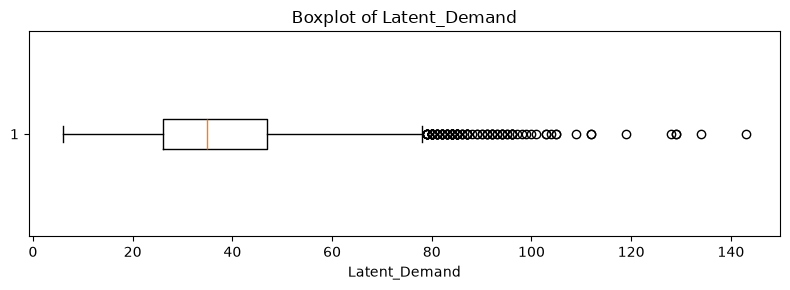

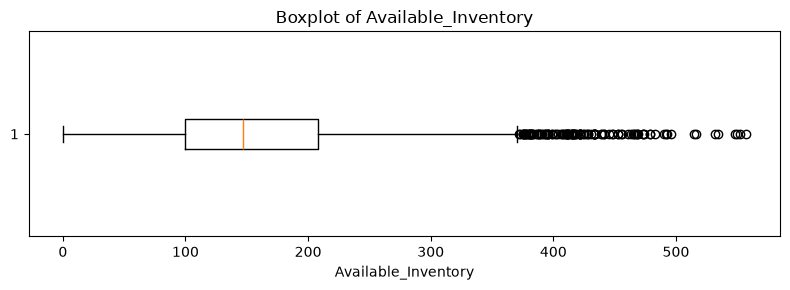

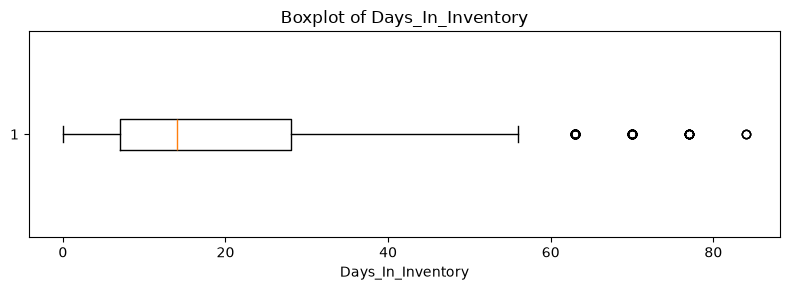

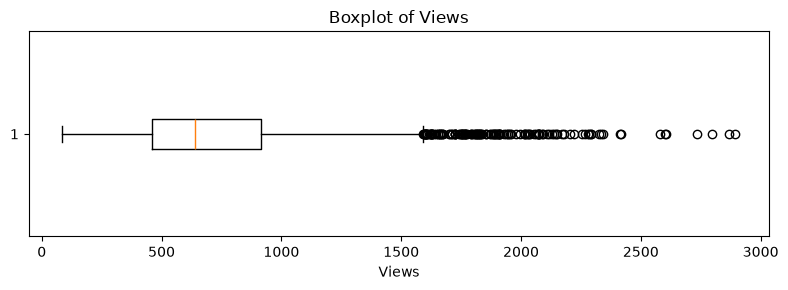

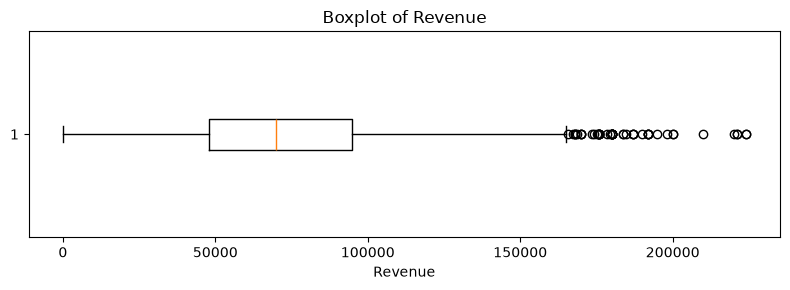

In [84]:
boxplot_cols = [
    "Latent_Demand",
    "Available_Inventory",
    "Days_In_Inventory",
    "Views",
    "Revenue"
]

for col in boxplot_cols:

    plt.figure(figsize=(8, 3))

    plt.boxplot(
        df[col],
        orientation="horizontal"
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

#### Top Observations for Latent Demand

In [80]:
display(
    df[
        [
            "Week_Start",
            "SKU_ID",
            "Product_Name",
            "Category",
            "Latent_Demand",
            "Units_Sold",
            "Discount_Pct",
            "Promotion_Type",
            "Retail_Event",
            "Stockout_Flag"
        ]
    ]
    .sort_values(
        "Latent_Demand",
        ascending=False
    )
    .head(15)
)

,Week_Start,SKU_ID,Product_Name,Category,Latent_Demand,Units_Sold,Discount_Pct,Promotion_Type,Retail_Event,Stockout_Flag
1352,2025-10-06,SKU013,Women Printed Kurta,Ethnic Wear,143,143,35,Festival Offer,Dussehra,0
3842,2025-03-10,SKU037,Vitamin C Face Wash,Beauty,134,134,30,Festival Offer,Holi,0
3875,2025-10-27,SKU037,Vitamin C Face Wash,Beauty,129,129,30,Festival Offer,Diwali,0
3872,2025-10-06,SKU037,Vitamin C Face Wash,Beauty,129,129,35,Festival Offer,Dussehra,0
3718,2024-10-28,SKU036,Matte Liquid Lip Colour,Beauty,128,128,30,Festival Offer,Diwali,0
12,2024-03-25,SKU001,Men Cotton T-Shirt,Apparel,119,119,40,Festival Offer,Holi,0
3819,2024-09-30,SKU037,Vitamin C Face Wash,Beauty,112,112,35,Festival Offer,Navratri,0
3770,2025-10-27,SKU036,Matte Liquid Lip Colour,Beauty,112,112,25,Festival Offer,Diwali,0
3883,2025-12-22,SKU037,Vitamin C Face Wash,Beauty,109,109,25,Festival Offer,Christmas,0
167,2025-03-10,SKU002,Women Ribbed Top,Apparel,105,105,15,Festival Offer,Holi,0


#### Top Observation for views

In [81]:
display(
    df[
        [
            "Week_Start",
            "SKU_ID",
            "Product_Name",
            "Views",
            "Cart_Adds",
            "Latent_Demand",
            "Discount_Pct",
            "Retail_Event"
        ]
    ]
    .sort_values(
        "Views",
        ascending=False
    )
    .head(15)
)

,Week_Start,SKU_ID,Product_Name,Views,Cart_Adds,Latent_Demand,Discount_Pct,Retail_Event
3883,2025-12-22,SKU037,Vitamin C Face Wash,2894,323,109,25,Christmas
92,2025-10-06,SKU001,Men Cotton T-Shirt,2868,334,93,25,Dussehra
3792,2024-03-25,SKU037,Vitamin C Face Wash,2797,326,87,15,Holi
3687,2024-03-25,SKU036,Matte Liquid Lip Colour,2733,318,91,25,Holi
3903,2024-05-06,SKU038,Onion Hair Serum,2605,399,81,40,NaN
1352,2025-10-06,SKU013,Women Printed Kurta,2599,331,143,35,Dussehra
1355,2025-10-27,SKU013,Women Printed Kurta,2581,237,104,20,Diwali
148,2024-10-28,SKU002,Women Ribbed Top,2418,368,83,25,Diwali
3838,2025-02-10,SKU037,Vitamin C Face Wash,2414,250,94,30,NaN
1354,2025-10-20,SKU013,Women Printed Kurta,2344,253,77,20,NaN


#### Top Observations for revenue

In [82]:
display(
    df[
        [
            "Week_Start",
            "SKU_ID",
            "Product_Name",
            "Revenue",
            "Units_Sold",
            "Selling_Price",
            "Discount_Pct",
            "Gross_Profit"
        ]
    ]
    .sort_values(
        "Revenue",
        ascending=False
    )
    .head(15)
)

,Week_Start,SKU_ID,Product_Name,Revenue,Units_Sold,Selling_Price,Discount_Pct,Gross_Profit
2687,2025-03-10,SKU026,Adult English Willow Cricket Bat,223988.80,14,15999.20,20,50388.80
2696,2025-05-12,SKU026,Adult English Willow Cricket Bat,223988.80,14,15999.20,20,50388.80
2694,2025-04-28,SKU026,Adult English Willow Cricket Bat,220988.95,13,16999.15,15,59788.95
2692,2025-04-14,SKU026,Adult English Willow Cricket Bat,220988.95,13,16999.15,15,59788.95
2688,2025-03-17,SKU026,Adult English Willow Cricket Bat,219989.00,11,19999.00,0,83589.00
2698,2025-05-26,SKU026,Adult English Willow Cricket Bat,209989.50,14,14999.25,25,36389.50
2695,2025-05-05,SKU026,Adult English Willow Cricket Bat,199990.00,10,19999.00,0,75990.00
2693,2025-04-21,SKU026,Adult English Willow Cricket Bat,199990.00,10,19999.00,0,75990.00
2697,2025-05-19,SKU026,Adult English Willow Cricket Bat,197990.10,11,17999.10,10,61590.10
2713,2025-09-08,SKU026,Adult English Willow Cricket Bat,194990.25,13,14999.25,25,33790.25


#### EDA Finding — Distribution and Outlier Review

- Several numerical variables are right-skewed, particularly Selling_Price, Views, Cart_Adds, Latent_Demand and inventory variables.
- IQR-based screening flags approximately 1–3% of observations as potential outliers for most variables.
- High-demand observations are largely associated with festivals, promotional periods and deeper discounts, suggesting that they represent valid demand spikes rather than data errors.
- High customer-interest observations also correspond to plausible high-demand or event-driven periods.
- Extreme Revenue values are primarily associated with naturally high-priced products rather than erroneous transactions.
- Therefore, no observations will be removed or capped solely based on global IQR thresholds.

**Preprocessing implication:** Potential outliers will be retained unless later model diagnostics show that they materially reduce model stability. Transformations or robust modelling techniques may be considered where appropriate, especially for highly skewed variables.

------------

## 12. EDA Conclusions and Modelling Implications

#### Objective
Summarize the main findings from exploratory analysis and convert them into
clear decisions for feature engineering and modelling.



#### Key Findings

- Demand differs significantly across SKUs and categories.
- Latent_Demand and Units_Sold are similar for most observations, but stockout periods cause observed sales to underestimate true demand.
- Demand varies over time and increases during several festival and retail-event periods.
- Promotions and deeper discounts are generally associated with higher demand.
- The discount-demand relationship remains positive across categories and most individual SKUs.
- Inventory behaviour differs across products; high inventory and stockout risk represent different business situations.
- Demand tends to be higher when our price is lower relative to competitors, although this relationship is weaker than the discount-demand relationship.
- Higher discounts increase demand but reduce margin and generally reduce gross profit.
- Views and Cart_Adds provide strong customer-interest signals, while Cart_Rate appears less informative.
- Several numerical variables are skewed and contain IQR-flagged extreme observations, but inspection indicates that these largely represent valid business behaviour rather than data-quality errors.
- No outlier removal or capping is required at this stage.

#### Feature Engineering Direction

The EDA supports creating:
- calendar and event features
- lag and rolling demand features
- pricing and competitor-gap features
- inventory-relative features
- historical customer-interest features

All engineered features must respect prediction-time availability and avoid leakage.

#### Conclusion

The dataset has been validated and explored sufficiently to proceed to feature engineering.

**Next Stage:** 03_feature_engineering.ipynb